In [1]:
Sys.unsetenv("PROJ_LIB")
Sys.unsetenv("GDAL_DATA")
library(dplyr)
library(sf)
library(ggplot2)
library(rnaturalearth)
library(rnaturalearthdata)
#library(rnaturalearthhires)
library(patchwork)
library(ggrepel)
library(tidyr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Linking to GEOS 3.14.1, GDAL 3.13.3, PROJ 9.9.0; sf_use_s2() is TRUE


Attaching package: ‘rnaturalearthdata’


The following object is masked from ‘package:rnaturalearth’:

    countries110




In [2]:
Sys.setenv(PROJ_LIB = "/users/akrinos/miniconda3/envs/spatial_env/share/proj")
Sys.setenv(GDAL_LIB = "/users/akrinos/miniconda3/envs/spatial_env/share/gdal")

In [3]:
file.exists(file.path(Sys.getenv("PROJ_LIB"), "proj.db"))

[1] TRUE

In [4]:
nerrs_metaT=read.csv("../output/metaT_informed_NERRS_20260926_1.csv")

In [5]:
nerrs_allometry=read.csv("../output/allometry_NERRS_20260926_1.csv")

In [6]:
nerrs_nutrients=read.csv("../data/nerrs_data_cleaned.csv")

In [7]:
nerrs_metadata=read.csv("../data/nerrs_all_metadata.csv")

In [8]:
head(nerrs_nutrients)

,X,DateTime,NERR.Site.ID,nitrogen,phosphorus
,<int>,<chr>,<chr>,<dbl>,<dbl>
1,1,2002-01-06,niw,6.620781,0.8759629
2,2,2002-01-07,del,86.662206,1.0909751
3,3,2002-01-07,niw,7.739472,0.6706490
4,4,2002-01-08,ace,4.473335,1.2606670
5,5,2002-01-09,ace,3.150131,0.9912819
6,6,2002-01-16,cbv,10.524625,0.5137230


In [9]:
nerrs_metadata$Parameters.Reported[1:4]

[1] "PO4F,NH4F,NO23F,CHLA_N,DIN,NO2F,NO3F"                                
[2] "Temp,SpCond,Sal,DO_pct,DO_mgl,Depth,cDepth,pH,Turb"                  
[3] "ATemp,RH,BP,WSpd,MaxWSpd,MaxWSpdT,Wdir,SDWDir,TotPAR,TotPrcp,CumPrcp"
[4] "PO4F,NH4F,NO23F,CHLA_N,DIN,NO2F,NO3F"

In [10]:
average_nutrients = nerrs_nutrients %>% dplyr::group_by(NERR.Site.ID) %>%
    dplyr::summarize(mean_nitrogen = mean(nitrogen,na.rm=TRUE),
                     sd_nitrogen = sd(nitrogen,na.rm=TRUE),
                     mean_phosphorus = mean(phosphorus,na.rm=TRUE),
                     sd_phosphorus = sd(phosphorus,na.rm=TRUE))
    

In [11]:
write.csv(nerrs_metadata %>% 
          dplyr::filter(grepl("PO4F",Parameters.Reported)&
                        grepl("NH4F",Parameters.Reported)&
                        ((grepl("NO2F",Parameters.Reported)&
                         grepl("NO3F",Parameters.Reported))|
                        grepl("NO23F",Parameters.Reported))) %>%
          dplyr::select(NERR.Site.ID,Station.Code,Station.Name,Latitude,
                                    Longitude, Reserve.Name,State) %>%
     dplyr::left_join(average_nutrients),"../data/nerrs_sites_attributes.csv",
          row.names=FALSE,quote=FALSE)

Joining with `by = join_by(NERR.Site.ID)`


In [11]:
nerrs_merged=nerrs_metaT %>%
    dplyr::filter(index>50) %>% 
    dplyr::rename(c("metaT"="abund")) %>%
    dplyr::inner_join(nerrs_allometry%>%
                     dplyr::rename(c("allometry"="abund")),
                    by=c("DateTime","taxon","Site"))

In [22]:
write.csv(nerrs_metadata %>% dplyr::select(NERR.Site.ID,Station.Code,Station.Name,Latitude,
                                    Longitude, Reserve.Name,State) %>%
     dplyr::left_join(average_nutrients) %>%
     dplyr::filter(NERR.Site.ID%in%unique(nerrs_merged$Site)),
          "../data/nerrs_sites_attributes.csv",
          row.names=FALSE,quote=FALSE)

Joining with `by = join_by(NERR.Site.ID)`


In [21]:
unique(nerrs_merged$Site)

[1] "wel" "kac" "job" "del" "tjr" "sap" "rkb" "mar" "ace" "cbm" "gtm" "hud"
[13] "wqb" "wkb" "cbv" "hee" "jac" "sos" "noc" "gnd" "grb" "sfb" "elk" "pdb"
[25] "nar"

In [12]:
corr_res = data.frame()
for (taxon_curr in (unique(nerrs_merged$taxon))) {
    for (site_curr in unique(nerrs_merged$Site)) {
        nerrs_merged_sub = nerrs_merged %>% dplyr::filter(taxon==taxon_curr) %>%
            dplyr::filter(Site==site_curr)
        corr_curr = cor.test(nerrs_merged_sub$metaT,nerrs_merged_sub$allometry,method="pearson")
        corr_res = corr_res %>% dplyr::bind_rows(data.frame(taxon=taxon_curr,
                                                 site=site_curr,
                                                 corr = corr_curr$estimate,
                                                 pval = corr_curr$p.value))
    }
}

In [13]:
infill_dates = read.csv("../output/metaT_informed_all_sol_haldane_20260925_10.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund))

infill_dates_allometry = read.csv("../output/../output/allometry_all_sol_haldane_20260925_10.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund))

merged_results = infill_dates %>% dplyr::rename(c(abund_metaT=abund)) %>%
    dplyr::left_join(infill_dates_allometry %>% dplyr::rename(c("abund_allom"=abund)),
                     by=c("DateTime","taxon")) %>%
    dplyr::filter(as.Date(DateTime,format="%Y-%m-%d")>as.Date("2000-03-01",format="%Y-%m-%d"))

Warning message:
“Removed 120405 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 120405 rows containing missing values or values outside the scale range
(`geom_point()`).”


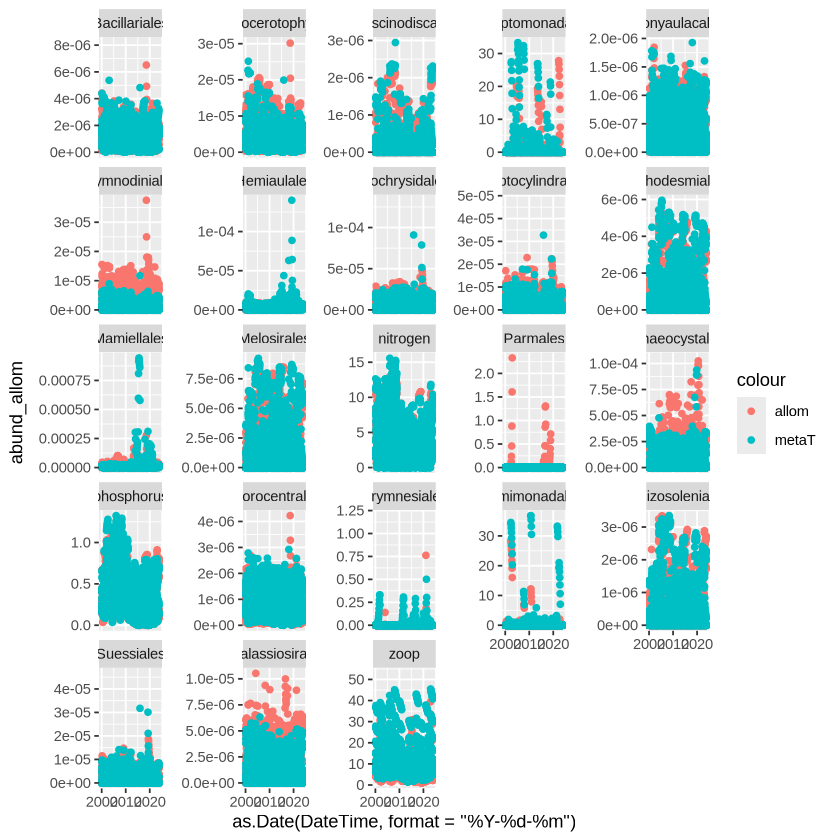

In [30]:
ggplot(merged_results) + geom_point(aes(x=as.Date(DateTime,format="%Y-%d-%m"),y=abund_allom,color="allom"))+ 
    geom_point(aes(x=as.Date(DateTime,format="%Y-%d-%m"),y=abund_metaT,color="metaT")) + 
    facet_wrap(~taxon,scales="free_y")

In [14]:
results_fr=data.frame()
for (taxon_curr in unique(merged_results$taxon)) {
    sub_fr = merged_results %>% dplyr::filter(taxon==taxon_curr)
    corr_curr = cor.test(sub_fr$abund_metaT,sub_fr$abund_allom,method="pearson")
    results_fr = results_fr %>%
        dplyr::bind_rows(data.frame("taxon"=taxon_curr,
                                     corr = corr_curr$estimate,
                                     pval = corr_curr$p.value))
}

In [30]:
bats_output_metaT = read.csv("../output/metaT_BATS_HOT_20261017.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund))

bats_output_allometry = read.csv("../output/allometry_BATS_HOT_20261017.csv")%>%
    dplyr::mutate(abund=case_when(abund<0~0,
                                  TRUE~abund))

bats_results = bats_output_metaT %>% dplyr::rename(c(abund_metaT=abund)) %>%
    dplyr::left_join(bats_output_allometry %>% dplyr::rename(c("abund_allom"=abund)),
                     by=c("DateTime","taxon","Site")) %>%
    dplyr::filter(as.Date(DateTime,format="%Y-%m-%d")>as.Date("2000-03-01",format="%Y-%m-%d"))

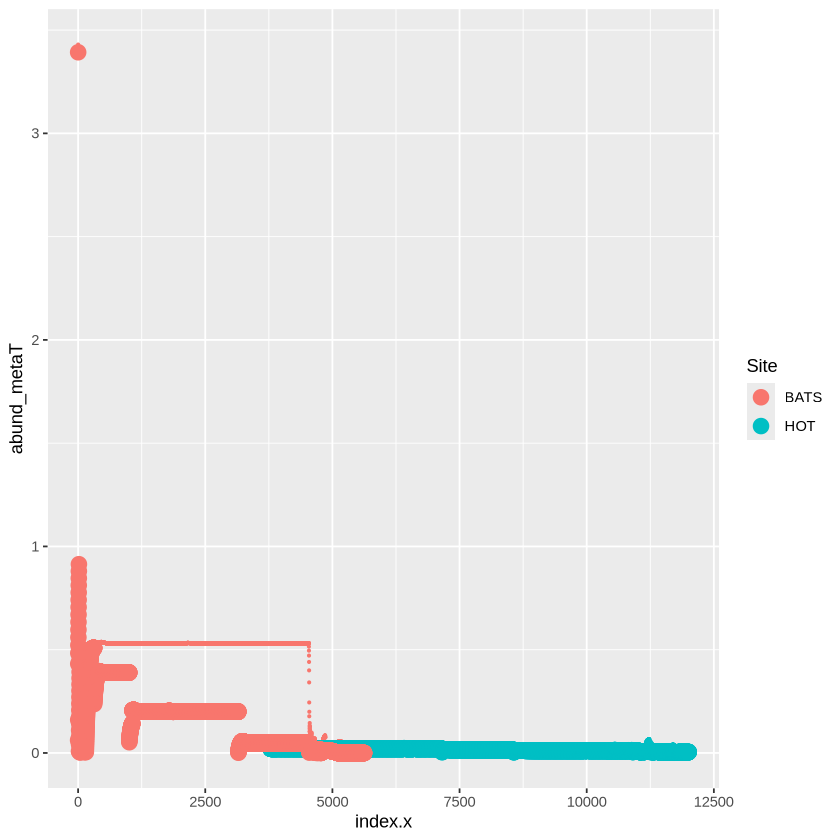

In [49]:
ggplot(bats_results %>% dplyr::filter(taxon=="nitrogen")) + #as.Date(DateTime,format="%Y-%m-d")
    geom_point(aes(x=index.x,y=abund_metaT,color=Site),size=0.5)+
    geom_point(aes(x=index.x,y=abund_allom,color=Site),size=4)

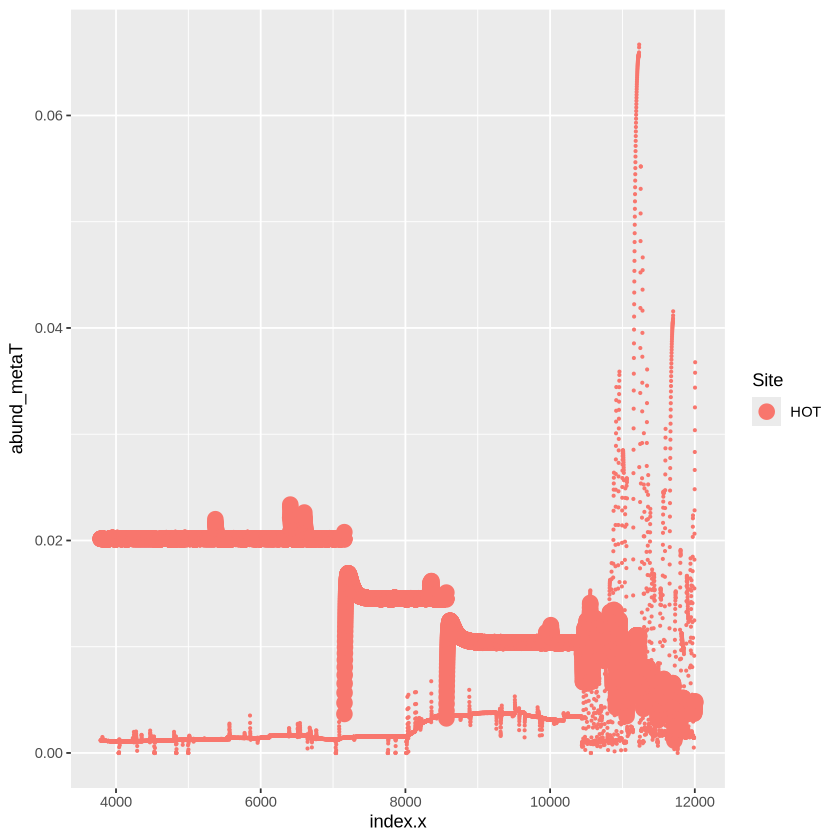

In [50]:
ggplot(bats_results %>% dplyr::filter(taxon=="nitrogen") %>% dplyr::filter(Site=="HOT")) + #as.Date(DateTime,format="%Y-%m-d")
    geom_point(aes(x=index.x,y=abund_metaT,color=Site),size=0.5)+
    geom_point(aes(x=index.x,y=abund_allom,color=Site),size=4)

In [31]:
results_fr_bats=data.frame()
for (taxon_curr in unique(bats_results$taxon)) {
    for (site_curr in unique(bats_results$Site)) {
        sub_fr = bats_results %>% dplyr::filter(taxon==taxon_curr) %>%
            dplyr::filter(Site==site_curr)
        corr_curr = cor.test(sub_fr$abund_metaT,sub_fr$abund_allom,method="pearson")
        results_fr_bats = results_fr_bats %>%
            dplyr::bind_rows(data.frame("taxon"=taxon_curr,
                                        "site"=site_curr,
                                         corr = corr_curr$estimate,
                                         pval = corr_curr$p.value))
    }
}

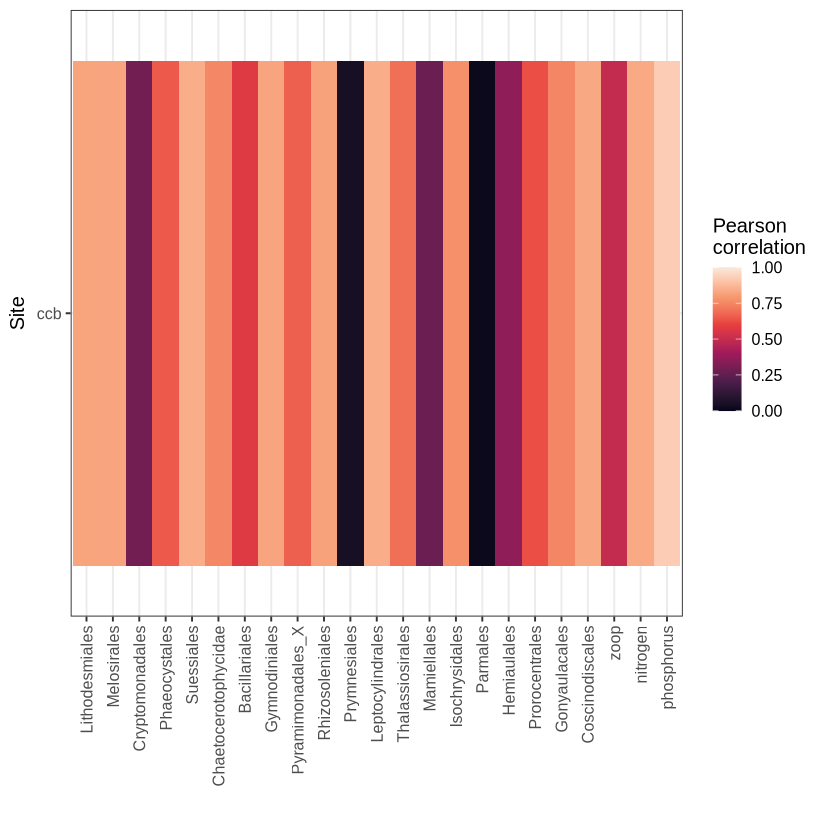

In [36]:
ggplot(results_fr %>% dplyr::mutate(site="ccb"))+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

In [32]:
results_fr_bats

,taxon,site,corr,pval
,<chr>,<chr>,<dbl>,<dbl>
cor...1,Bacillariales,HOT,-0.35390618,4.230301e-241
cor...2,Bacillariales,BATS,0.99992795,0.000000e+00
cor...3,Thalassiosirales,HOT,0.75285843,0.000000e+00
cor...4,Thalassiosirales,BATS,0.99998895,0.000000e+00
cor...5,Gonyaulacales,HOT,0.64945395,0.000000e+00
cor...6,Gonyaulacales,BATS,0.99999935,0.000000e+00
cor...7,Isochrysidales,HOT,0.76748709,0.000000e+00
cor...8,Isochrysidales,BATS,0.99455237,0.000000e+00
cor...9,Melosirales,HOT,0.59490604,0.000000e+00


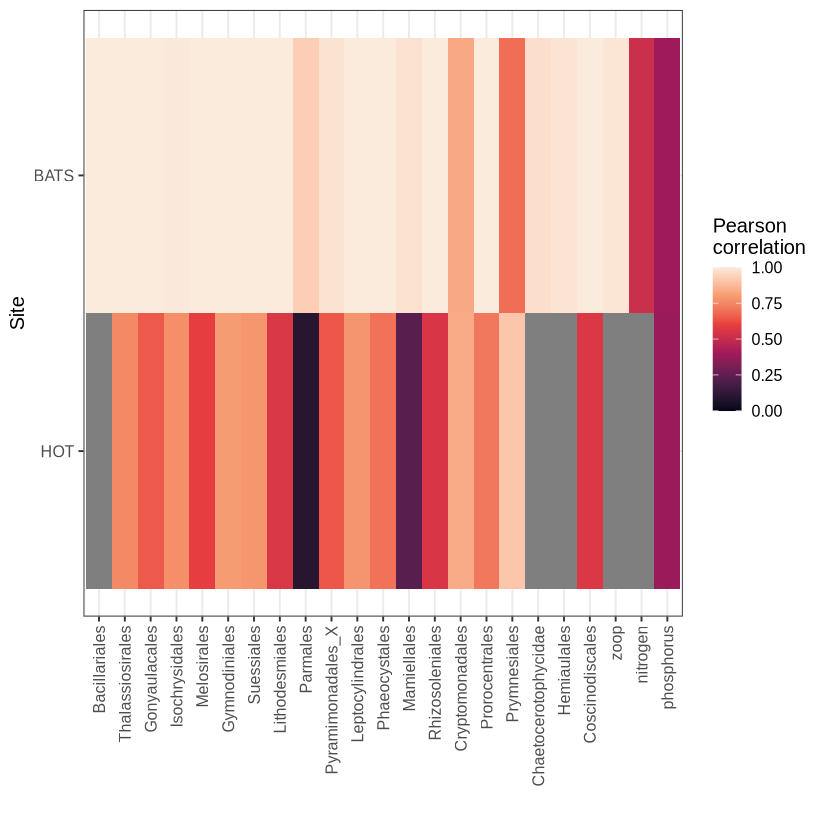

In [33]:
ggplot(results_fr_bats)+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

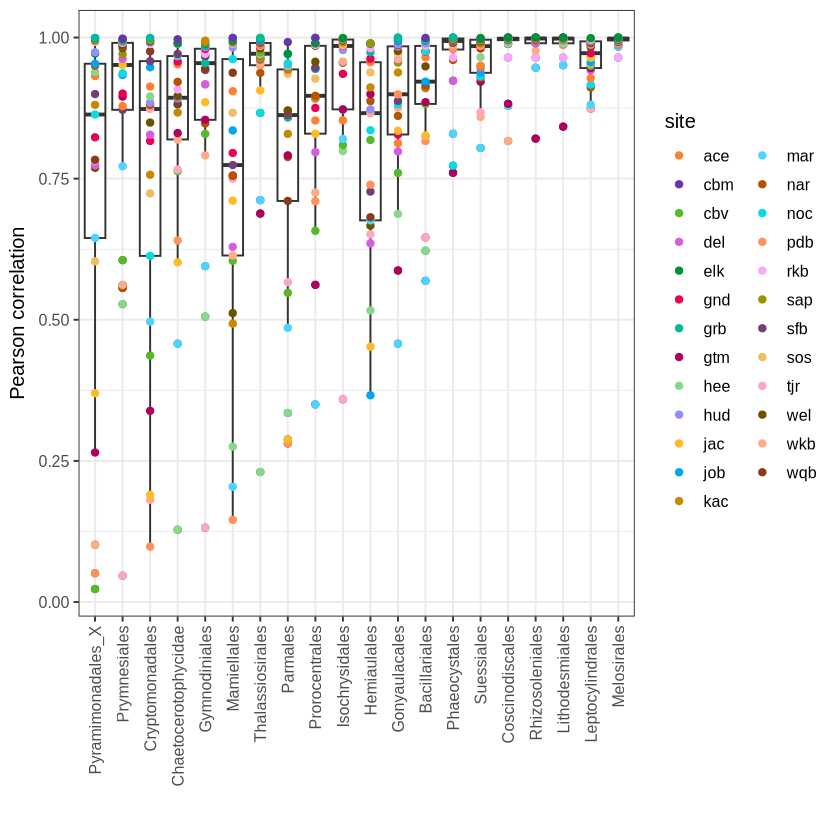

In [12]:
ggplot(corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr))+ 
    geom_boxplot(aes(x=factor(taxon,levels=unique(taxon)),group=taxon,y=corr))+ 
    geom_point(aes(x=factor(taxon,levels=unique(taxon)),color=site,group=site,y=corr))+ 
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Pearson correlation") + xlab("") + 
    scale_color_manual(values=c("#ff8030",
"#6836ab",
"#57b928",
"#d45de2",
"#009238",
"#e90057",
"#01bb99",
"#b0005f",
"#88d88c",
"#908fff",
"#fcbb27",
"#02a6eb",
"#c98800",
"#4ad4ff",
"#b75300",
"#08dbe2",
"#ff925c",
"#fca7ff",
"#979500",
"#733f76",
"#f2bd61",
"#ffa7bb",
"#6d5200",
"#ffab85",
"#883c1d",
"#9a5d4d"))

Saving 6.67 x 6.67 in image


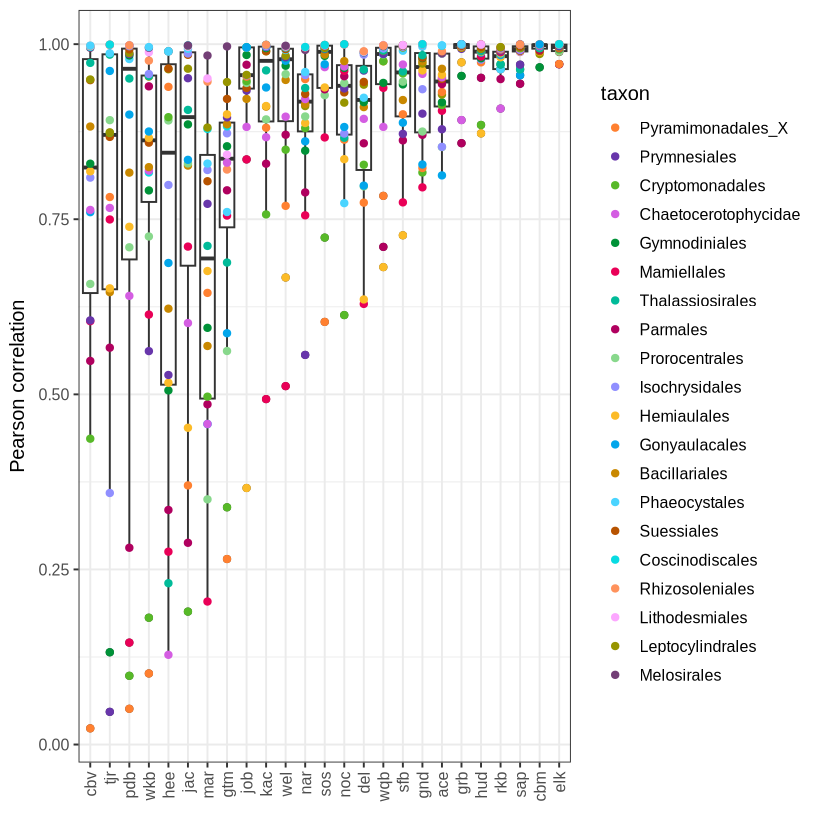

In [20]:
ggplot(corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr))+ 
    geom_boxplot(aes(x=factor(site,levels=unique(site)),y=corr))+ 
    geom_point(aes(color=factor(taxon,levels=unique(taxon)),
                   x=factor(site,levels=unique(site)),group=site,y=corr))+ 
    theme_bw(base_size=12) + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Pearson correlation") + xlab("") + 
    scale_color_manual(values=c("#ff8030",
"#6836ab",
"#57b928",
"#d45de2",
"#009238",
"#e90057",
"#01bb99",
"#b0005f",
"#88d88c",
"#908fff",
"#fcbb27",
"#02a6eb",
"#c98800",
"#4ad4ff",
"#b75300",
"#08dbe2",
"#ff925c",
"#fca7ff",
"#979500",
"#733f76",
"#f2bd61",
"#ffa7bb",
"#6d5200",
"#ffab85",
"#883c1d",
"#9a5d4d"),name="taxon")

ggsave("../figures/compare_taxa_nerrs.pdf")

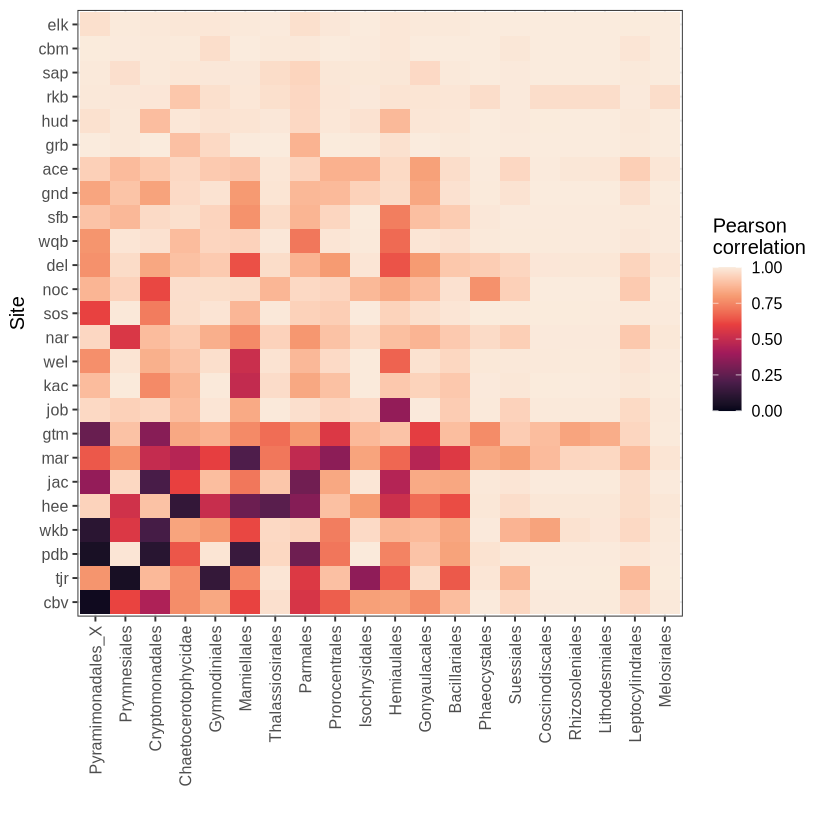

In [13]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)
ggplot(for_tile)+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

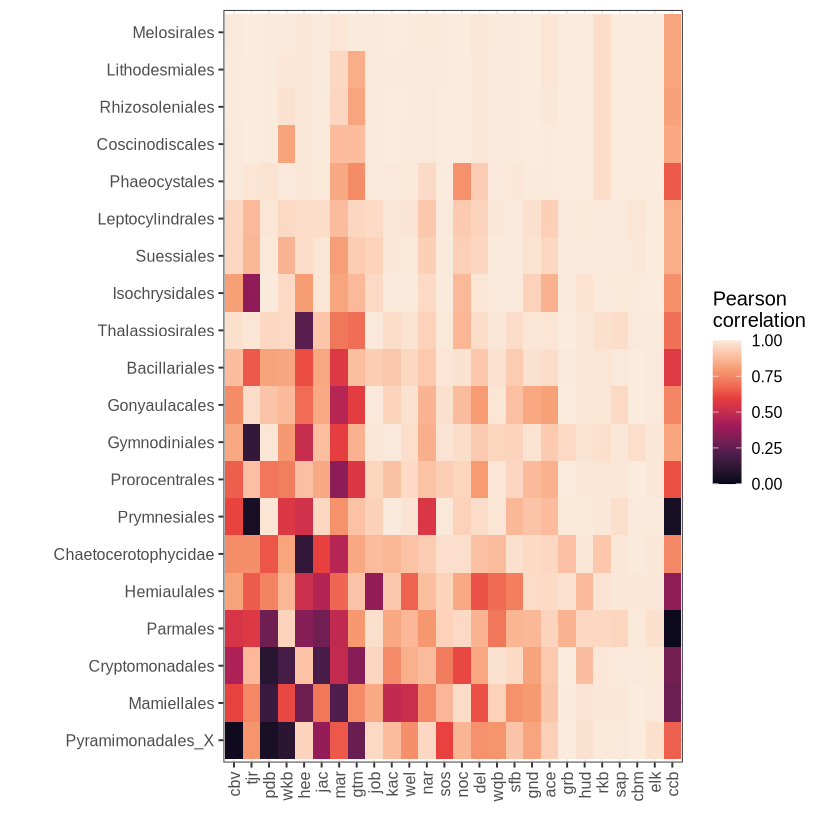

In [40]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)

summarize_corr_site = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(site) %>% dplyr::summarize(avg_corr = min(corr)) %>%
    dplyr::arrange(avg_corr)

summarize_corr_taxon = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
    dplyr::group_by(taxon) %>% dplyr::summarize(avg_corr = mean(corr)) %>%
    dplyr::arrange(avg_corr)

rotate_tile = ggplot(for_tile %>% dplyr::bind_rows(results_fr%>% 
                                                   dplyr::mutate(site="ccb")) %>% 
                     dplyr::filter(taxon%in%unique(summarize_corr_taxon$taxon)))+ 
    geom_tile(aes(y=factor(taxon,levels=unique(summarize_corr_taxon$taxon)),
                  x=factor(site,levels=c(unique(summarize_corr_site$site),"ccb")),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_viridis_c(option = "rocket", 
                                                  limits = c(0, 1),direction = 1,
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("") + xlab("")

rotate_tile

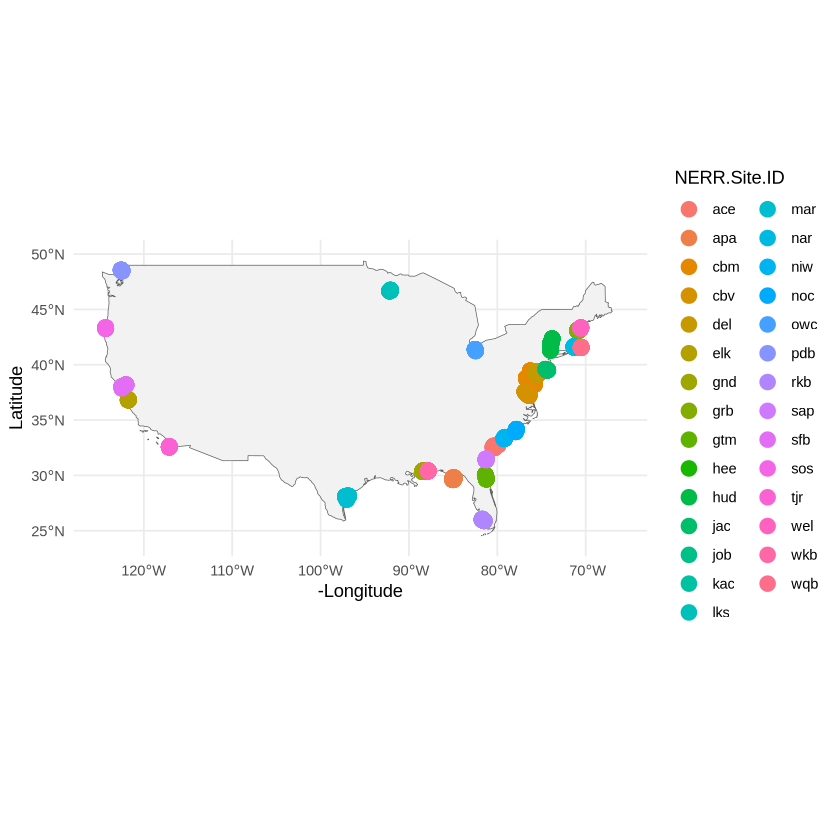

In [15]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

ggplot() +
  geom_sf(data = usa, fill = "gray95") +
  geom_point(data = nerrs_metadata, aes(x = -Longitude, y = Latitude,col=NERR.Site.ID), size = 4) +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50)) + # Zoom into mainland USA
  theme_minimal()

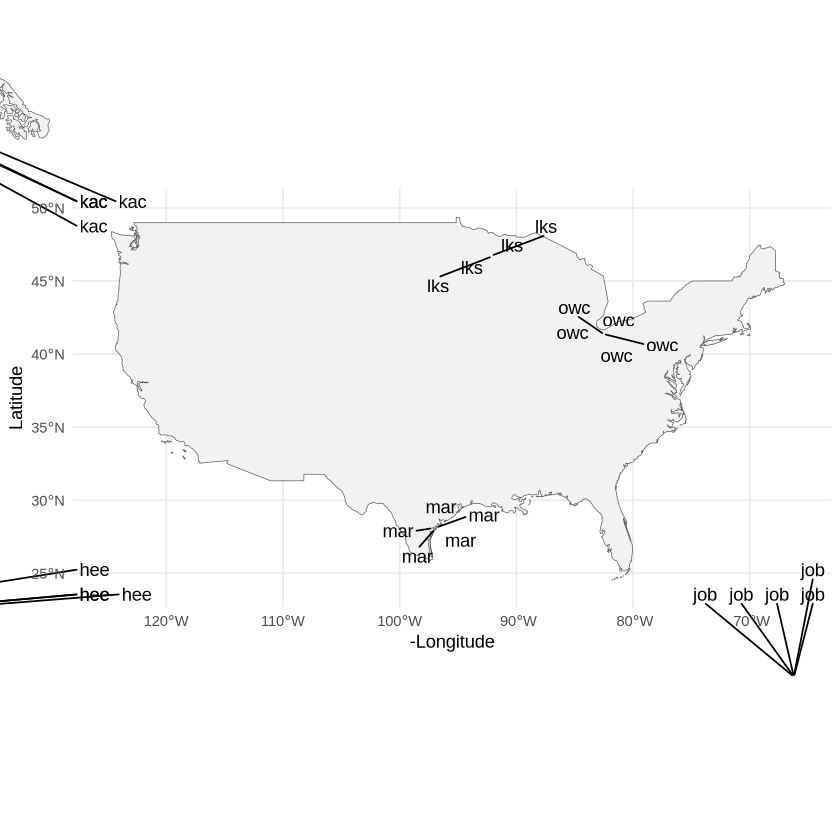

In [26]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

ggplot() +
  geom_sf(data = usa, fill = "gray95") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::mutate(Latitude=round(Latitude,2),
                          Longitude=round(Longitude,2)) %>%
            dplyr::distinct(Latitude,Longitude,NERR.Site.ID), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID)) +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50),clip = "off") + # Zoom into mainland USA
  theme_minimal()

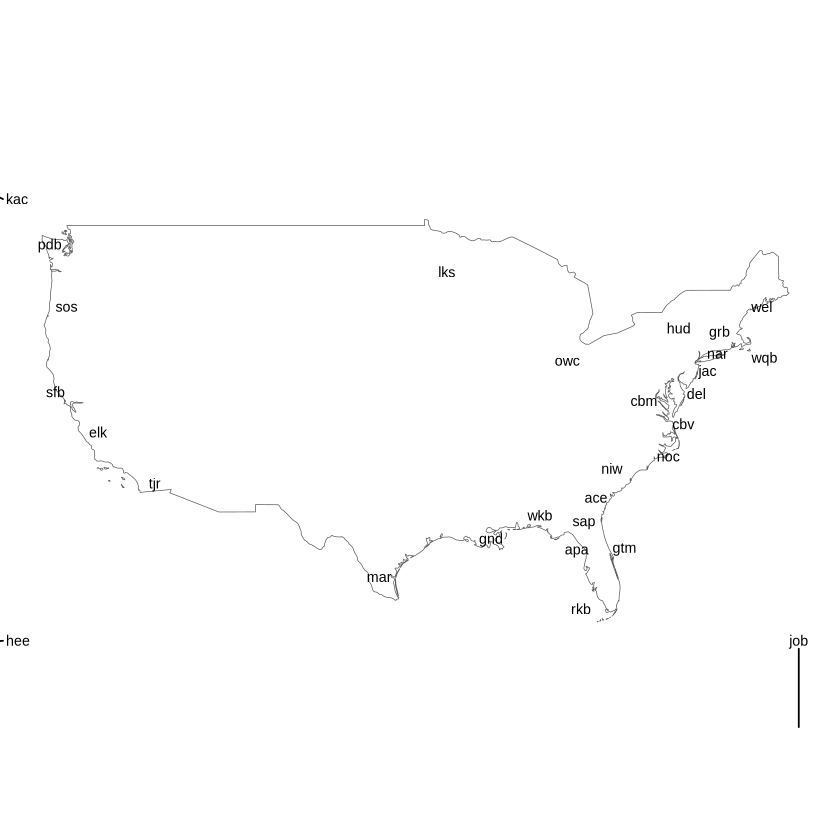

In [18]:
usa <- ne_countries(country = "United States of America", scale = "medium", returnclass = "sf")

map_plt = ggplot() +
  geom_sf(data = usa, fill = "white") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::group_by(NERR.Site.ID)%>%
            dplyr::summarize(Latitude=mean(Latitude),
                             Longitude=mean(Longitude)), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID),
    max.overlaps = Inf,size=3) +
  coord_sf(xlim = c(-125, -66), ylim = c(24, 50),clip = "off") + # Zoom into mainland USA
  theme_void() + xlab("") + ylab("")
map_plt

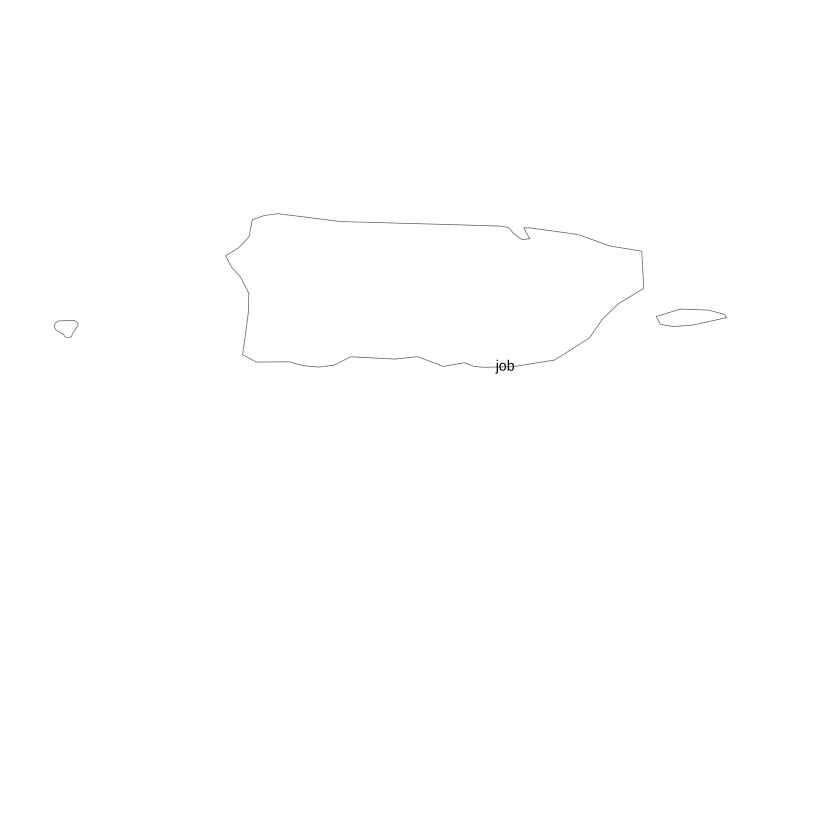

In [51]:
caribbean_map <- ne_countries(scale = "medium", type = "map_units", returnclass = "sf")

# Filter specifically for Puerto Rico
puerto_rico <- caribbean_map[caribbean_map$name == "Puerto Rico", ]

map_plt = ggplot() +
  geom_sf(data = puerto_rico, fill = "white") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::group_by(NERR.Site.ID)%>%
            dplyr::summarize(Latitude=mean(Latitude),
                             Longitude=mean(Longitude)) %>% dplyr::filter(NERR.Site.ID=="job"), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID),
    max.overlaps = Inf,size=3) +
  coord_sf(xlim = c(-68, -65), ylim = c(17.5,18),clip = "off") + # Zoom into mainland USA
  theme_void() + xlab("") + ylab("")
map_plt

In [55]:
usa

ERROR while rich displaying an object: Error in loadNamespace(x): there is no package called ‘geojsonio’

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = 

featurecla      scalerank labelrank sovereignt               sov_a3 adm0_dif
17 Admin-0 country 5         2         United States of America US1    1       
   level type    tlc admin                    geometry                       ⋯
17 2     Country 1   United States of America MULTIPOLYGON (((-132.7469 5... ⋯
   fclass_tr fclass_id fclass_pl fclass_gr fclass_it fclass_nl fclass_se
17 NA        NA        NA        NA        NA        NA        NA       
   fclass_bd fclass_ua geometry                      
17 NA        NA        MULTIPOLYGON (((-132.7469 5...

In [58]:
us_states <- ne_states(country = "united states of america", returnclass = "sf")

# 2. Filter strictly for Alaska
alaska_map <- us_states[us_states$name == "Alaska", ]

map_plt = ggplot() +
  geom_sf(data = alaska_map, fill = "white") +
  geom_text_repel(data = nerrs_metadata %>%
            dplyr::group_by(NERR.Site.ID)%>%
            dplyr::summarize(Latitude=mean(Latitude),
                             Longitude=mean(Longitude)) %>% dplyr::filter(NERR.Site.ID=="kac"), 
            aes(x = -Longitude, y = Latitude,label=NERR.Site.ID),
    max.overlaps = Inf,size=3) +
  coord_sf(xlim = c(-160,-150), ylim = c(59,61),clip = "off") + # Zoom into mainland USA
  theme_void() + xlab("") + ylab("")
map_plt

The rnaturalearthhires package needs to be installed.
Installing the rnaturalearthhires package.
there is no package called ‘pak’


ERROR: Error in loadNamespace(x): there is no package called ‘rnaturalearthhires’


In [72]:
## read in environmental phosphate abundances
phos_ptown = read.csv("../data/phosphorus.csv")
phos_ptown = read.csv("../data/nutrients/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/nutrients/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))

phos_ptown_dt = phos_ptown%>% dplyr::filter(PARAM_CODE=="PO4") %>% 
    dplyr::filter(DEPTH<5)
phos_ptown_dt = phos_ptown_dt %>% dplyr::group_by(Date,STAT_ID) %>%
    dplyr::summarize(phosphorus = mean(FFU_RESULT))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

## read in environmental nitrate/nitrite/ammonium abundances
nitr_ptown = read.csv("../data/nitrogen.csv")
nitr_ptown = read.csv("../data/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
nitr_ptown_dt = nitr_ptown%>% dplyr::filter(DEPTH<5)

nitr_ptown_dt = nitr_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NO2","NO3","NO3+NO2")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

nitr_ptown_dt = nitr_ptown_dt %>% 
    dplyr::rename(c("NO3_NO2"="NO3+NO2")) %>%
    dplyr::mutate(nitrate = case_when(is.na(NO3_NO2) ~ NO3+NO2,
                                      TRUE~NO3_NO2))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

ammon_ptown = read.csv("../data/nitrogen.csv")
ammon_ptown = read.csv("../data/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
ammon_ptown_dt = ammon_ptown %>% dplyr::filter(DEPTH<5)

ammon_ptown_dt = ammon_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NH4")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

ammon_ptown_dt = ammon_ptown_dt %>% 
    dplyr::rename(c("ammonium"="NH4")) %>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date and STAT_ID.
ℹ Output is grouped by Date.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, STAT_ID))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by PARAM_CODE, STAT_ARRIV, STAT_ID, and Date.
ℹ Output is grouped by PARAM_CODE, STAT_ARRIV, and STAT_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(PARAM_CODE, STAT_ARRIV, STAT_ID, Date))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by PARAM_CODE, STAT_ARRIV, STAT_ID, and Date.
ℹ Output is grouped by PARAM_CODE, STAT_ARRIV, and STAT_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(PARAM_CODE, STAT_ARRIV, STAT_ID, Date))` for
  per-operation groupi

In [75]:
n_frame = ammon_ptown_dt %>% dplyr::left_join(nitr_ptown_dt) %>%
        dplyr::filter(!is.na(ammonium)&!is.na(nitrate)) %>%
        dplyr::mutate(nitrogen = ammonium + nitrate)

all_nutrients = n_frame %>% dplyr::select(STAT_ARRIV,STAT_ID,SampleDate,nitrogen)%>% 
    dplyr::left_join(phos_ptown_dt) %>% dplyr::mutate(NERR.Site.ID="ccb")

Joining with `by = join_by(STAT_ARRIV, STAT_ID, Date, SampleDate)`
Joining with `by = join_by(STAT_ID, SampleDate)`
Warning message in dplyr::left_join(., phos_ptown_dt):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 4 of `x` matches multiple rows in `y`.
ℹ Row 453 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 73 rows containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 73 rows containing missing values or values outside the scale range
(`geom_point()`).”


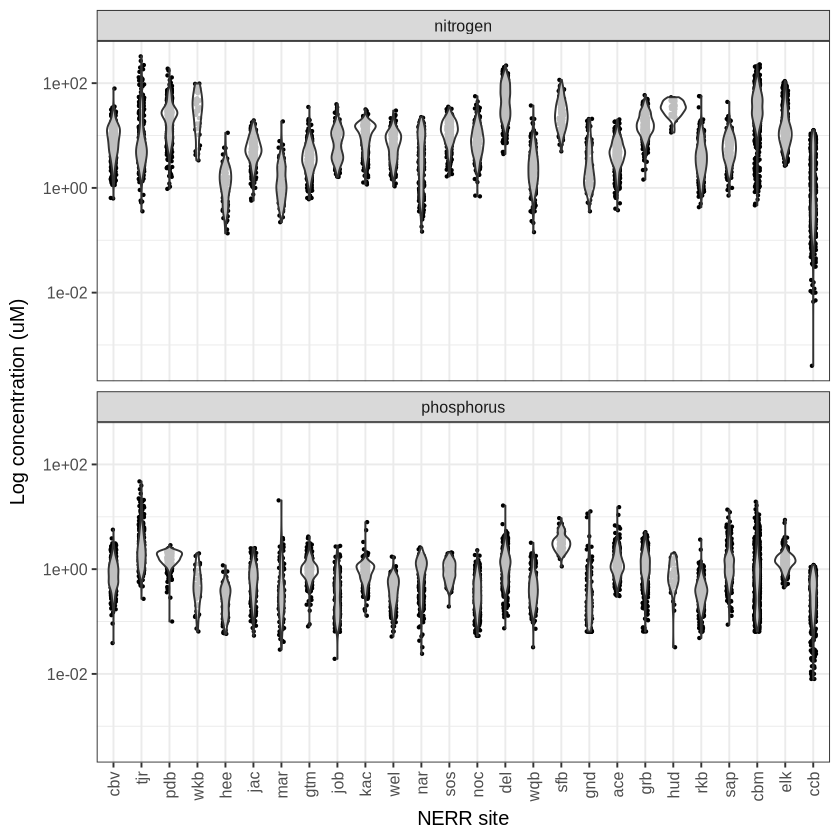

In [83]:
nutrient_box = ggplot(nerrs_nutrients %>%
       dplyr::bind_rows(all_nutrients) %>%
       dplyr::filter(NERR.Site.ID %in% unique(c(for_tile$site,"ccb"))) %>%
       dplyr::mutate(DateT=as.Date(DateTime,format="%Y-%m-%d")) %>%
       tidyr::pivot_longer(cols = starts_with("nitrogen")|starts_with("phosphorus"),
                           names_to = "species",
                           values_to = "uM")) + 
       geom_jitter(aes(x=factor(NERR.Site.ID,levels=c(unique(summarize_corr_site$site),"ccb")),y=uM),
                   height=0,width=0.1,size=0.5) +
       geom_violin(aes(x=factor(NERR.Site.ID,levels=c(unique(summarize_corr_site$site),"ccb")),y=uM),
                   alpha=0.75,fill="white") +
    facet_wrap(~species,nrow=2)+
    scale_y_log10()+ 
    theme_bw(base_size=12) + xlab("NERR site")+
    ylab("Log concentration (uM)") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))
nutrient_box

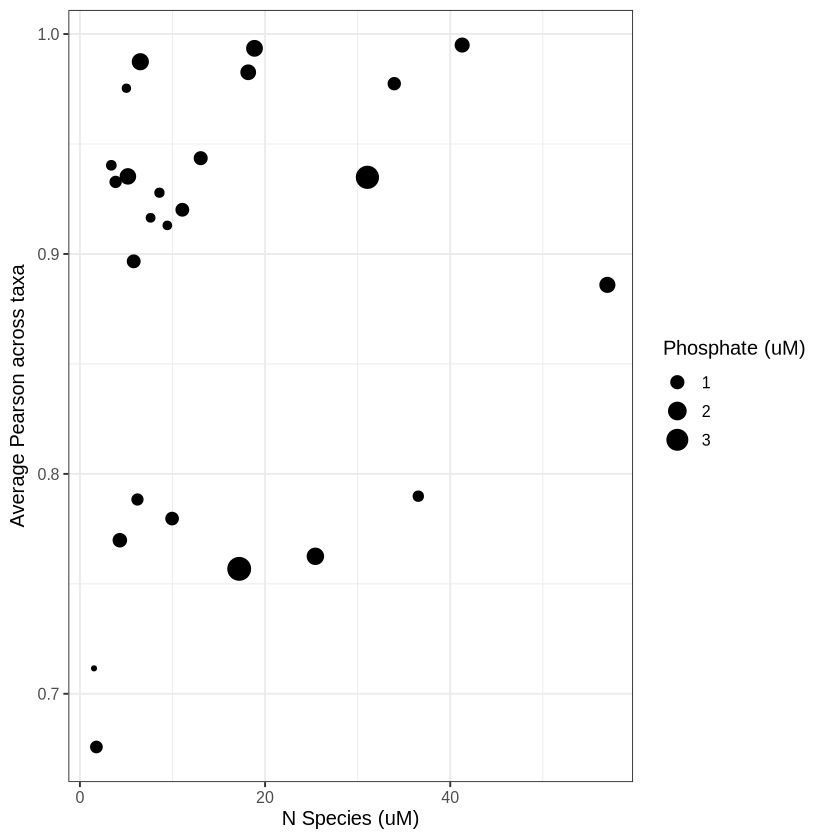

In [18]:
ggplot(nerrs_nutrients %>%
       dplyr::filter(NERR.Site.ID %in% unique(for_tile$site)) %>%
       dplyr::mutate(DateT=as.Date(DateTime,format="%Y-%m-%d")) %>%
    dplyr::group_by(NERR.Site.ID) %>%
    dplyr::summarize(nitrogen=mean(nitrogen),phosphorus=mean(phosphorus)) %>%
    dplyr::left_join(summarize_corr_site,by=c("NERR.Site.ID"="site"))) + 
    geom_point(aes(x=nitrogen,y=avg_corr,size=phosphorus)) + 
    theme_bw(base_size=12) + 
    ylab("Average Pearson across taxa") + xlab("N Species (uM)") + 
    scale_size(name="Phosphate (uM)")

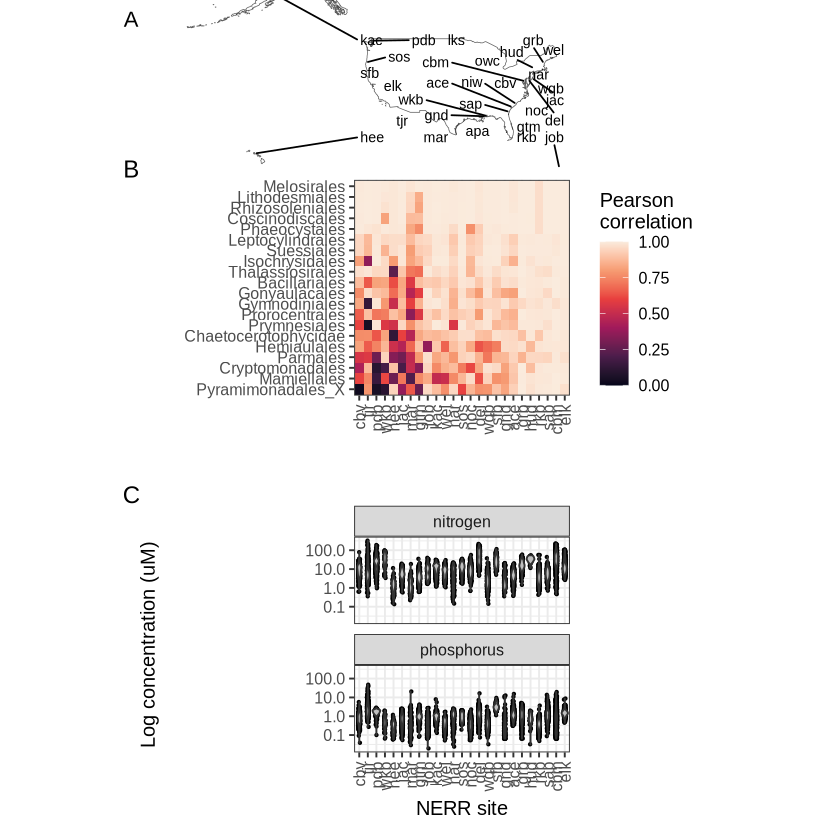

In [19]:
(map_plt/rotate_tile/nutrient_box)+plot_annotation(tag_levels = "A")
ggsave("../figures/figure_4_nutrients.pdf",width=10,height=12,units="in")

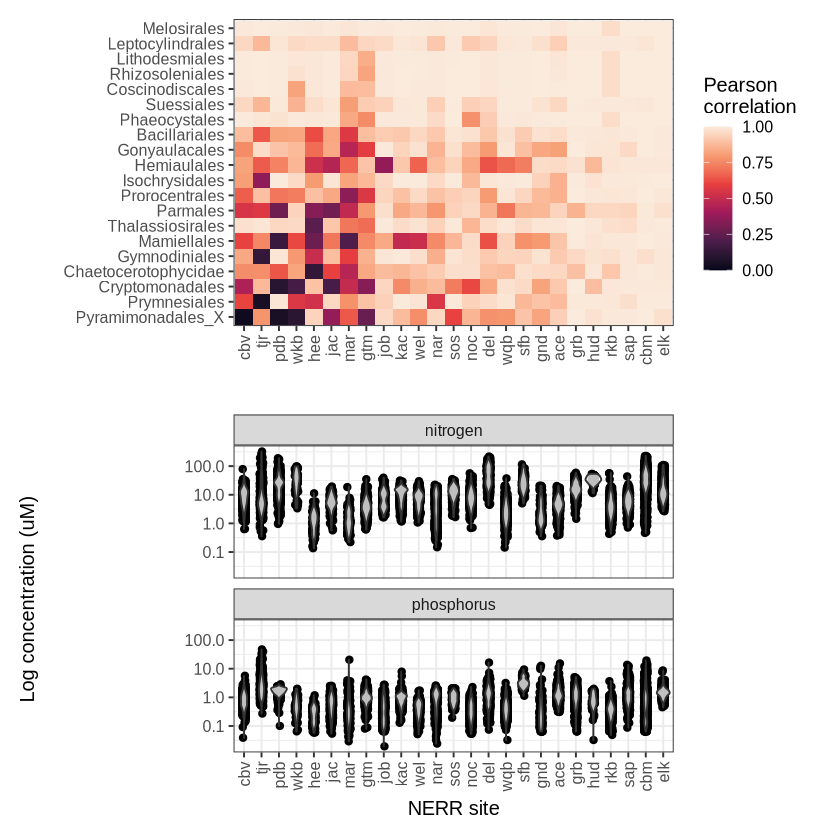

In [31]:
rotate_tile/nutrient_box

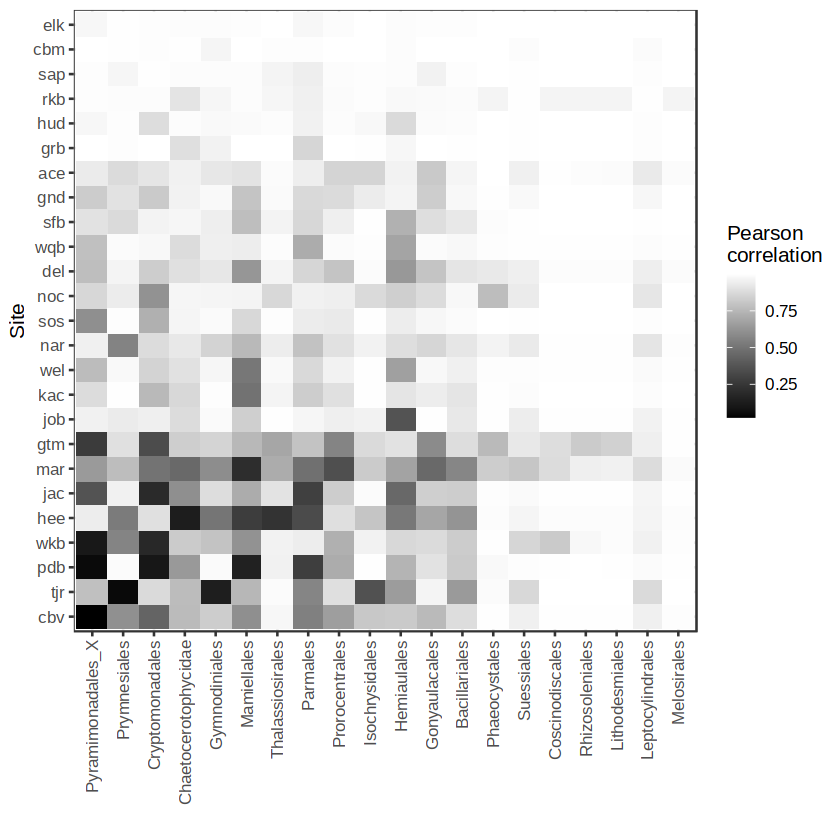

In [59]:
for_tile = corr_res %>% dplyr::filter(!(taxon%in%c("nitrogen","phosphorus","zoop"))) %>%
       dplyr::arrange(corr)
ggplot(for_tile)+ 
    geom_tile(aes(x=factor(taxon,levels=unique(taxon)),
                  y=factor(site,levels=unique(site)),fill=corr))+ 
    theme_bw(base_size=12) + scale_fill_gradient(low="black",high="white",
                                                  name="Pearson\ncorrelation") +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    ylab("Site") + xlab("")

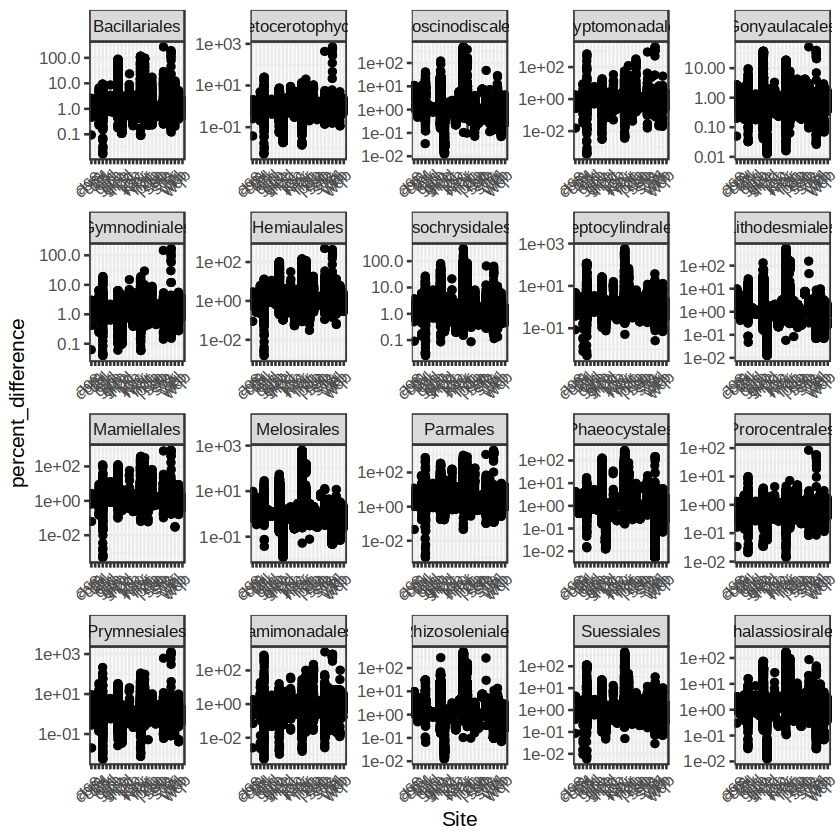

In [5]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=Site,y=percent_difference))+
    geom_jitter(aes(Site,y=percent_difference),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    facet_wrap(~taxon,scales="free") + 
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [1]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_jitter(aes(taxon,y=percent_difference,color=Site),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    facet_wrap(~Site) + 
    scale_y_log10() + 
    theme_bw(base_size=12)+ ylab("ratio allometry to metaT") + 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

ERROR: Error in ggplot(nerrs_merged %>% dplyr::mutate(percent_difference = allometry/metaT) %>% : could not find function "ggplot"


Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 58898 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 58898 rows containing missing values or values outside the scale range
(`geom_point()`).”


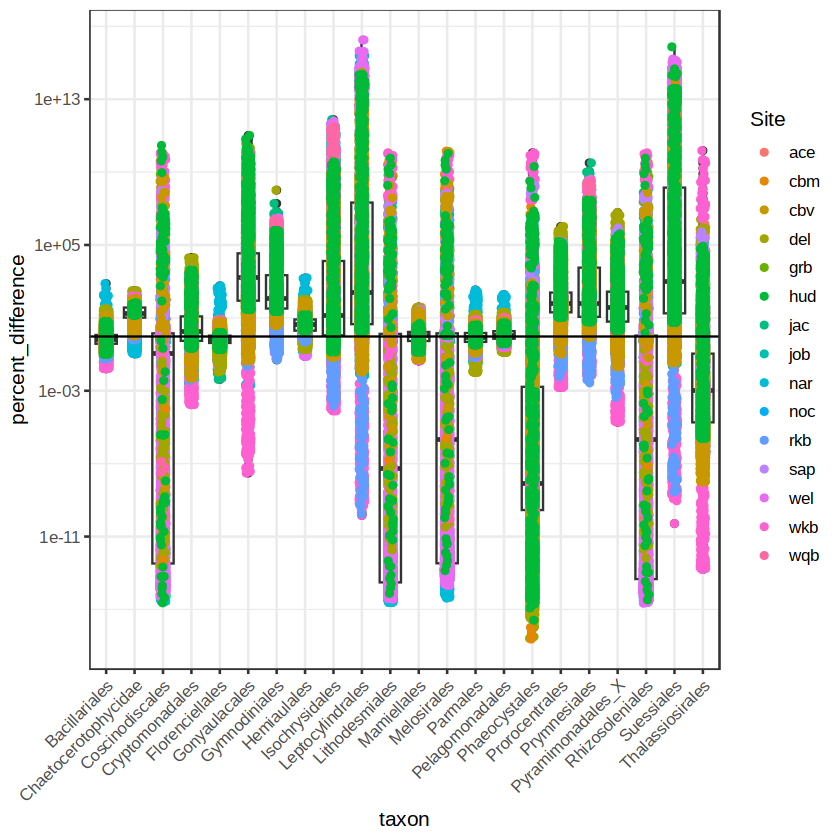

In [7]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_jitter(aes(taxon,y=percent_difference,color=Site),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

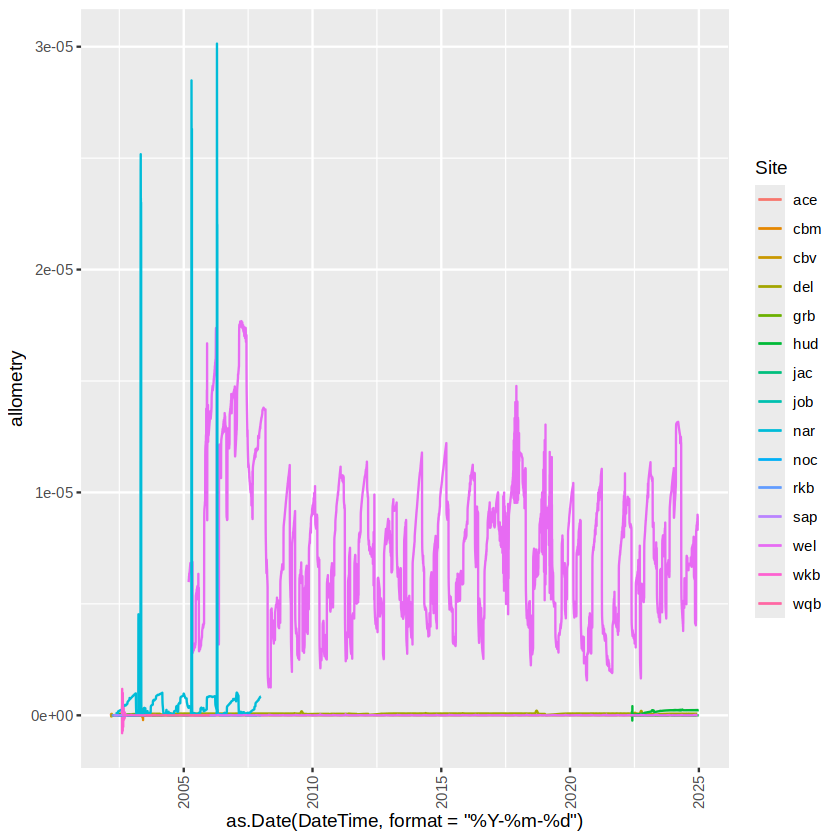

In [8]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Gonyaulacales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site))+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

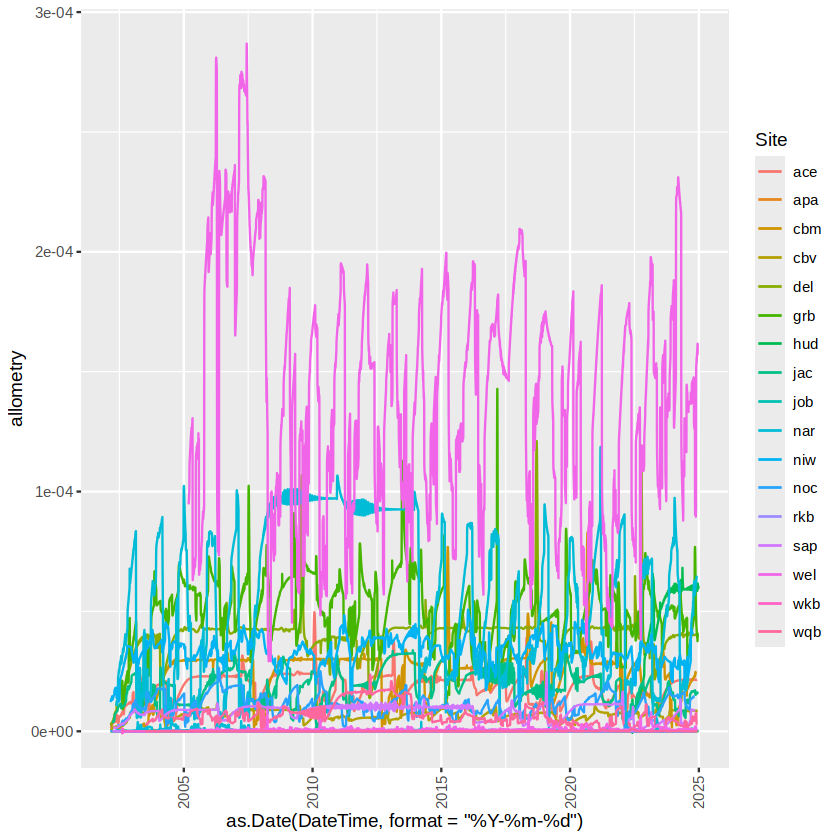

In [7]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Prorocentrales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site))+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

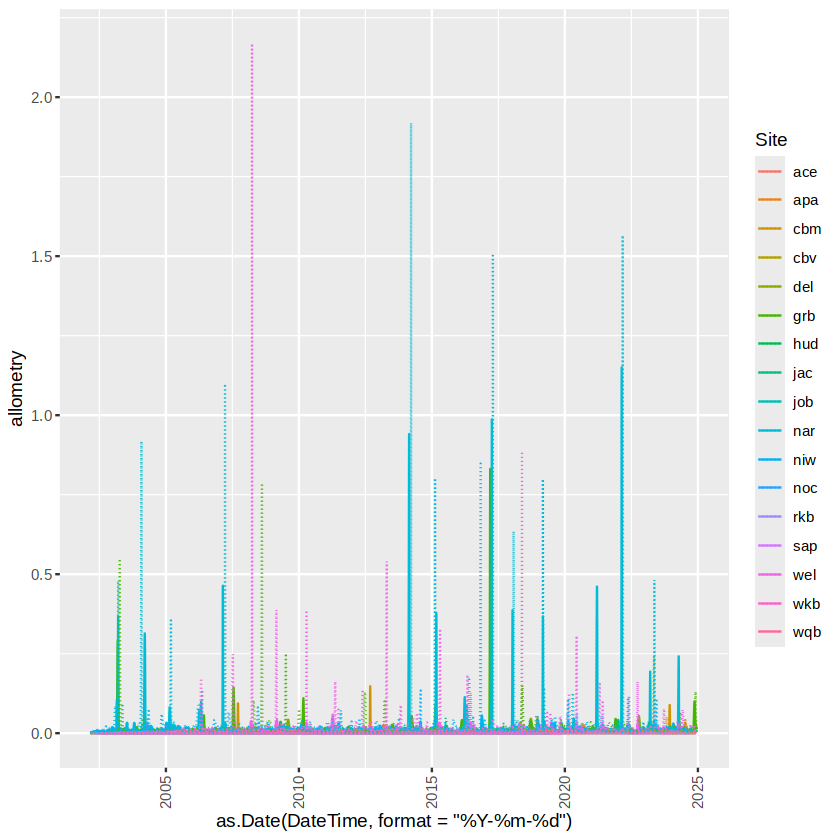

In [9]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Isochrysidales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site),linetype="dotted")+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

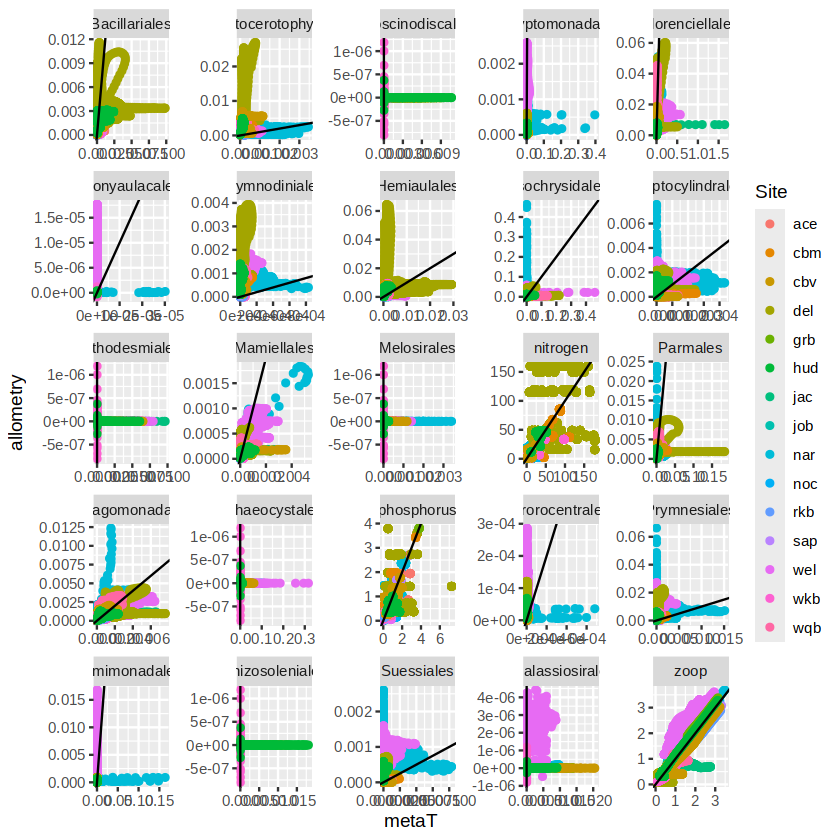

In [9]:
ggplot(nerrs_merged) + 
    geom_point(aes(x=metaT,y=allometry,color=Site))+
    geom_abline(aes(intercept=0,slope=1))+
    facet_wrap(~taxon,scales="free")

In [13]:
unique(nerrs_merged$Site)

[1] "ace" "wqb" "hud" "cbv" "wel" "noc" "cbm" "nar" "niw" "job" "jac" "rkb"
[13] "apa" "grb" "sap" "del" "wkb"